In [65]:
import requests
import json
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import plotly.graph_objects as go

In [66]:
url = "https://api.openalex.org/works"

fsu_id = "https://api.openalex.org/I103163165"

In [67]:
params = {
    "filter": f"institutions.id:{fsu_id},from_publication_date:2021-01-01,to_publication_date:2026-12-31"
}

In [68]:
params["select"] = "id,doi,display_name,publication_year,publication_date,type,cited_by_count,authorships,primary_location,open_access,concepts,primary_topic"

In [69]:
count = 0

In [70]:
params["per-page"] = 100
params["cursor"] = "*"

with open("fsu_works_2021_2026.jsonl", "w") as file:

    while True:
        response = requests.get(url, params=params)
        data = response.json()

        works = data["results"]

        for work in works:
            file.write(json.dumps(work) + "\n")
            count += 1

        next_cursor = data["meta"]["next_cursor"]

        if next_cursor is None:
            break

        params["cursor"] = next_cursor

print("Saved", count, "works")

Saved 27830 works


In [71]:
print(count)

27830


In [72]:
import pandas as pd

df = pd.read_json("fsu_works_2021_2026.jsonl", lines=True)

In [73]:
df

,id,doi,display_name,publication_year,publication_date,type,cited_by_count,authorships,primary_location,open_access,concepts,primary_topic
0,https://openalex.org/W2963002078,https://doi.org/10.1093/ptep/ptac097,Review of Particle Physics,2022,2022-08-01,article,6044,"[{'author_position': 'first', 'author': {'id':...","{'id': 'doi:10.1093/ptep/ptac097', 'is_oa': Tr...","{'is_oa': True, 'oa_status': 'gold', 'oa_url':...","[{'id': 'https://openalex.org/C121332964', 'wi...","{'id': 'https://openalex.org/T10048', 'display..."
1,https://openalex.org/W4401211033,https://doi.org/10.1103/physrevd.110.030001,Review of Particle Physics,2024,2024-08-01,article,3592,"[{'author_position': 'first', 'author': {'id':...","{'id': 'doi:10.1103/physrevd.110.030001', 'is_...","{'is_oa': True, 'oa_status': 'hybrid', 'oa_url...","[{'id': 'https://openalex.org/C109214941', 'wi...","{'id': 'https://openalex.org/T10048', 'display..."
2,https://openalex.org/W3108936441,https://doi.org/10.1080/15548627.2020.1797280,Guidelines for the use and interpretation of a...,2021,2021-01-02,article,2742,"[{'author_position': 'first', 'author': {'id':...","{'id': 'doi:10.1080/15548627.2020.1797280', 'i...","{'is_oa': True, 'oa_status': 'bronze', 'oa_url...","[{'id': 'https://openalex.org/C203522944', 'wi...","{'id': 'https://openalex.org/T10587', 'display..."
3,https://openalex.org/W4387440676,https://doi.org/10.1021/acs.jcim.3c01153,AmberTools,2023,2023-10-08,article,2179,"[{'author_position': 'first', 'author': {'id':...","{'id': 'doi:10.1021/acs.jcim.3c01153', 'is_oa'...","{'is_oa': True, 'oa_status': 'hybrid', 'oa_url...","[{'id': 'https://openalex.org/C41008148', 'wik...","{'id': 'https://openalex.org/T12044', 'display..."
4,https://openalex.org/W3193988690,https://doi.org/10.1063/5.0055522,Software for the frontiers of quantum chemistr...,2021,2021-08-23,article,1436,"[{'author_position': 'first', 'author': {'id':...","{'id': 'doi:10.1063/5.0055522', 'is_oa': True,...","{'is_oa': True, 'oa_status': 'bronze', 'oa_url...","[{'id': 'https://openalex.org/C2777904410', 'w...","{'id': 'https://openalex.org/T10002', 'display..."
...,...,...,...,...,...,...,...,...,...,...,...,...
27825,https://openalex.org/W7220708563,https://doi.org/10.25582/data.2020-11.2090659/...,Data for EMSL Project 50414 from November 2020,2026,2026-10-06,dataset,0,"[{'author_position': 'first', 'author': {'id':...",{'id': 'doi:10.25582/data.2020-11.2090659/1712...,"{'is_oa': True, 'oa_status': 'green', 'oa_url'...",[],None
27826,https://openalex.org/W7220716127,https://doi.org/10.5194/egusphere-2026-5350-su...,"Supplementary material to ""Drizzle drives mode...",2026,2026-10-06,supplementary-materials,0,"[{'author_position': 'first', 'author': {'id':...",{'id': 'doi:10.5194/egusphere-2026-5350-supple...,"{'is_oa': True, 'oa_status': 'gold', 'oa_url':...","[{'id': 'https://openalex.org/C2779345167', 'w...","{'id': 'https://openalex.org/T10347', 'display..."
27827,https://openalex.org/W7220716511,https://doi.org/10.1029/2026ms005908,Two Localization Strategies for Sequential MCM...,2026,2026-10-01,article,0,"[{'author_position': 'first', 'author': {'id':...","{'id': 'doi:10.1029/2026ms005908', 'is_oa': Tr...","{'is_oa': True, 'oa_status': 'gold', 'oa_url':...","[{'id': 'https://openalex.org/C24552861', 'wik...","{'id': 'https://openalex.org/T10466', 'display..."
27828,https://openalex.org/W7220739726,https://doi.org/10.1515/9783111574462-011,16216311 A Neuroscience Perspective on Consume...,2026,2026-10-06,book-chapter,0,"[{'author_position': 'first', 'author': {'id':...","{'id': 'doi:10.1515/9783111574462-011', 'is_oa...","{'is_oa': False, 'oa_status': 'closed', 'oa_ur...","[{'id': 'https://openalex.org/C12713177', 'wik...","{'id': 'https://openalex.org/T13355', 'display..."


In [74]:
df.to_csv("fsu_works_2021_2026.csv")

In [75]:
df.head()

,id,doi,display_name,publication_year,publication_date,type,cited_by_count,authorships,primary_location,open_access,concepts,primary_topic
0,https://openalex.org/W2963002078,https://doi.org/10.1093/ptep/ptac097,Review of Particle Physics,2022,2022-08-01,article,6044,"[{'author_position': 'first', 'author': {'id':...","{'id': 'doi:10.1093/ptep/ptac097', 'is_oa': Tr...","{'is_oa': True, 'oa_status': 'gold', 'oa_url':...","[{'id': 'https://openalex.org/C121332964', 'wi...","{'id': 'https://openalex.org/T10048', 'display..."
1,https://openalex.org/W4401211033,https://doi.org/10.1103/physrevd.110.030001,Review of Particle Physics,2024,2024-08-01,article,3592,"[{'author_position': 'first', 'author': {'id':...","{'id': 'doi:10.1103/physrevd.110.030001', 'is_...","{'is_oa': True, 'oa_status': 'hybrid', 'oa_url...","[{'id': 'https://openalex.org/C109214941', 'wi...","{'id': 'https://openalex.org/T10048', 'display..."
2,https://openalex.org/W3108936441,https://doi.org/10.1080/15548627.2020.1797280,Guidelines for the use and interpretation of a...,2021,2021-01-02,article,2742,"[{'author_position': 'first', 'author': {'id':...","{'id': 'doi:10.1080/15548627.2020.1797280', 'i...","{'is_oa': True, 'oa_status': 'bronze', 'oa_url...","[{'id': 'https://openalex.org/C203522944', 'wi...","{'id': 'https://openalex.org/T10587', 'display..."
3,https://openalex.org/W4387440676,https://doi.org/10.1021/acs.jcim.3c01153,AmberTools,2023,2023-10-08,article,2179,"[{'author_position': 'first', 'author': {'id':...","{'id': 'doi:10.1021/acs.jcim.3c01153', 'is_oa'...","{'is_oa': True, 'oa_status': 'hybrid', 'oa_url...","[{'id': 'https://openalex.org/C41008148', 'wik...","{'id': 'https://openalex.org/T12044', 'display..."
4,https://openalex.org/W3193988690,https://doi.org/10.1063/5.0055522,Software for the frontiers of quantum chemistr...,2021,2021-08-23,article,1436,"[{'author_position': 'first', 'author': {'id':...","{'id': 'doi:10.1063/5.0055522', 'is_oa': True,...","{'is_oa': True, 'oa_status': 'bronze', 'oa_url...","[{'id': 'https://openalex.org/C2777904410', 'w...","{'id': 'https://openalex.org/T10002', 'display..."


In [76]:
df.groupby("publication_year").size().sort_index()

publication_year
2021    4251
2022    4178
2023    4389
2024    4605
2025    4987
2026    5420
dtype: int64

Publication counts dipped slightly from 4,250 in 2021 to 4,177 in 2022, then increased each year to 5,432 in 2026. This suggests growing FSU publication output in the dataset, although 2026 is still incomplete and its count may change.


In [77]:
df.iloc[4]["primary_location"]["source"]["display_name"]

'The Journal of Chemical Physics'

In [78]:
df["venue"] = df["primary_location"].apply(lambda location: (location["source"] or {}).get("display_name"))

In [79]:
df.groupby("venue").size().sort_values(ascending=False).head(20)

venue
DOE Pacific Northwest National Laboratory (PNNL) Repository    1063
arXiv (Cornell University)                                      897
SSRN Electronic Journal                                         784
Zenodo (CERN European Organization for Nuclear Research)        494
bioRxiv (Cold Spring Harbor Laboratory)                         407
Cambridge University Press eBooks                               357
Springer eBooks                                                 302
Journal of High Energy Physics                                  213
Research Square                                                 198
Innovation in Aging                                             174
Physical review. B./Physical review. B                          174
Cureus                                                          162
Nature Communications                                           142
Physical Review Letters                                         140
Physical Review C                         

The DOE Pacific Northwest National Laboratory Repository has the most works (1,059), followed by arXiv (890) and SSRN Electronic Journal (784). Repositories and preprint platforms feature prominently among the top venues, showing that these records capture research shared through several types of outlets, beyond traditional journals.


In [80]:
df["cited_by_count"].describe()

count    27830.000000
mean         9.112900
std         57.808599
min          0.000000
25%          0.000000
50%          1.000000
75%          7.000000
max       6044.000000
Name: cited_by_count, dtype: float64

Citation counts are strongly right-skewed: the mean is 9.10, compared with a median of 1, and the standard deviation is 57.76. The quartiles are 0, 1, and 7 citations, while counts range from 0 to 6,046, indicating that a small number of highly cited works raise the average; newer works have also had less time to accumulate citations.


In [81]:
df["primary_field"] = df["primary_topic"].apply(lambda topic: ((topic or {}).get("field") or {}).get("display_name"))

In [82]:
field_counts = pd.DataFrame(df.groupby("primary_field").size().to_frame(name="count").sort_values(by="count", ascending=False).head(10))

In [83]:
field_counts

,count
primary_field,
Social Sciences,3774
Medicine,3670
Psychology,2325
Physics and Astronomy,2241
Engineering,1911
Earth and Planetary Sciences,1586
Environmental Science,1519
Computer Science,1402
"Biochemistry, Genetics and Molecular Biology",1307


In [84]:
field_counts["share"] = field_counts["count"].apply(lambda field: field/len(df)*100)

In [85]:
field_counts

,count,share
primary_field,,
Social Sciences,3774,13.560905
Medicine,3670,13.187208
Psychology,2325,8.354294
Physics and Astronomy,2241,8.052461
Engineering,1911,6.866691
Earth and Planetary Sciences,1586,5.698886
Environmental Science,1519,5.458139
Computer Science,1402,5.037729
"Biochemistry, Genetics and Molecular Biology",1307,4.696371


Social Sciences leads with 3,777 works (13.56% of all works), closely followed by Medicine with 3,676 (13.20%). The top 10 fields span social sciences, health, physical sciences, engineering, and humanities, reflecting breadth in FSU research; these shares measure publication volume rather than research quality.


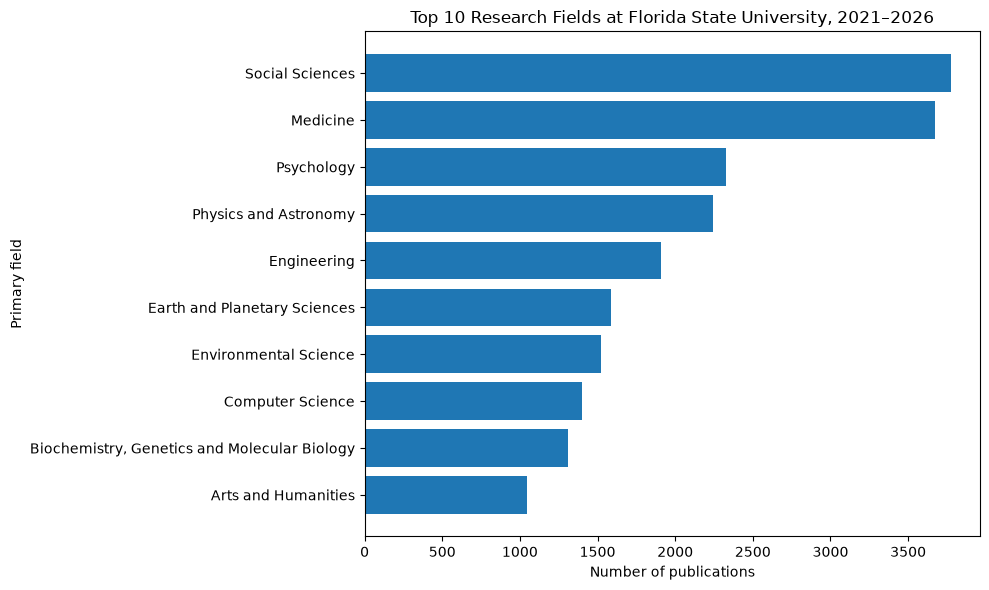

In [86]:
plt.figure(figsize=(10,6))
plt.barh(field_counts.index[::-1], field_counts["count"].iloc[::-1])
plt.title("Top 10 Research Fields at Florida State University, 2021–2026")
plt.xlabel("Number of publications")
plt.ylabel("Primary field")
plt.tight_layout()
plt.show()

Social Sciences and Medicine have the most publications among the top 10 fields. The chart hides changes over time and excludes fields outside the top 10.

In [87]:
top_five = field_counts.index[:5]
top_five

Index(['Social Sciences', 'Medicine', 'Psychology', 'Physics and Astronomy',
       'Engineering'],
      dtype='str', name='primary_field')

In [88]:
top_five_works = df[df["primary_field"].isin(top_five)]
top_five_works

,id,doi,display_name,publication_year,publication_date,type,cited_by_count,authorships,primary_location,open_access,concepts,primary_topic,venue,primary_field
0,https://openalex.org/W2963002078,https://doi.org/10.1093/ptep/ptac097,Review of Particle Physics,2022,2022-08-01,article,6044,"[{'author_position': 'first', 'author': {'id':...","{'id': 'doi:10.1093/ptep/ptac097', 'is_oa': Tr...","{'is_oa': True, 'oa_status': 'gold', 'oa_url':...","[{'id': 'https://openalex.org/C121332964', 'wi...","{'id': 'https://openalex.org/T10048', 'display...",Progress of Theoretical and Experimental Physics,Physics and Astronomy
1,https://openalex.org/W4401211033,https://doi.org/10.1103/physrevd.110.030001,Review of Particle Physics,2024,2024-08-01,article,3592,"[{'author_position': 'first', 'author': {'id':...","{'id': 'doi:10.1103/physrevd.110.030001', 'is_...","{'is_oa': True, 'oa_status': 'hybrid', 'oa_url...","[{'id': 'https://openalex.org/C109214941', 'wi...","{'id': 'https://openalex.org/T10048', 'display...",Physical review. D/Physical review. D.,Physics and Astronomy
2,https://openalex.org/W3108936441,https://doi.org/10.1080/15548627.2020.1797280,Guidelines for the use and interpretation of a...,2021,2021-01-02,article,2742,"[{'author_position': 'first', 'author': {'id':...","{'id': 'doi:10.1080/15548627.2020.1797280', 'i...","{'is_oa': True, 'oa_status': 'bronze', 'oa_url...","[{'id': 'https://openalex.org/C203522944', 'wi...","{'id': 'https://openalex.org/T10587', 'display...",Autophagy,Medicine
4,https://openalex.org/W3193988690,https://doi.org/10.1063/5.0055522,Software for the frontiers of quantum chemistr...,2021,2021-08-23,article,1436,"[{'author_position': 'first', 'author': {'id':...","{'id': 'doi:10.1063/5.0055522', 'is_oa': True,...","{'is_oa': True, 'oa_status': 'bronze', 'oa_url...","[{'id': 'https://openalex.org/C2777904410', 'w...","{'id': 'https://openalex.org/T10002', 'display...",The Journal of Chemical Physics,Physics and Astronomy
5,https://openalex.org/W3171954900,https://doi.org/10.1002/acr.24596,2021 American College of Rheumatology Guidelin...,2021,2021-06-08,article,1359,"[{'author_position': 'first', 'author': {'id':...","{'id': 'doi:10.1002/acr.24596', 'is_oa': False...","{'is_oa': True, 'oa_status': 'green', 'oa_url'...","[{'id': 'https://openalex.org/C71924100', 'wik...","{'id': 'https://openalex.org/T10200', 'display...",Arthritis Care & Research,Medicine
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
27817,https://openalex.org/W7220465608,https://doi.org/10.1073/pnas.2602080123,Extended fractional Hofstadter states at high ...,2026,2026-10-05,article,0,"[{'author_position': 'first', 'author': {'id':...","{'id': 'doi:10.1073/pnas.2602080123', 'is_oa':...","{'is_oa': True, 'oa_status': 'hybrid', 'oa_url...","[{'id': 'https://openalex.org/C66870719', 'wik...","{'id': 'https://openalex.org/T10657', 'display...",Proceedings of the National Academy of Sciences,Physics and Astronomy
27818,https://openalex.org/W7220469259,https://doi.org/10.7910/dvn/dcts91,"CES 2024, Team Module of Florida State Univers...",2026,2026-10-05,dataset,0,"[{'author_position': 'first', 'author': {'id':...","{'id': 'doi:10.7910/dvn/dcts91', 'is_oa': True...","{'is_oa': True, 'oa_status': 'green', 'oa_url'...","[{'id': 'https://openalex.org/C48103436', 'wik...","{'id': 'https://openalex.org/T10108', 'display...",Harvard Dataverse,Social Sciences
27819,https://openalex.org/W7220673998,https://doi.org/10.5281/zenodo.23191710,A Three-Layer Multimodal Accessibility Framewo...,2026,2026-10-06,software,0,"[{'author_position': 'first', 'author': {'id':...","{'id': 'doi:10.5281/zenodo.23191710', 'is_oa':...","{'is_oa': True, 'oa_status': 'green', 'oa_url'...","[{'id': 'https://openalex.org/C41008148', 'wik...","{'id': 'https://openalex.org/T12481', 'display...",Zenodo (CERN European Organization for Nuclear...,Social Sciences
27820,https://openalex.org/W7220676882,https://doi.org/10.1021/acs.chemmater.6c01539,3 d Transition Metal Con

In [89]:
yearly_counts = top_five_works.groupby(["publication_year", "primary_field"]).size()

In [90]:
yearly_counts = yearly_counts.unstack(fill_value=0).sort_index()
yearly_counts

primary_field,Engineering,Medicine,Physics and Astronomy,Psychology,Social Sciences
publication_year,,,,,
2021,298,479,322,415,653
2022,313,484,364,384,590
2023,313,543,376,387,601
2024,369,694,441,355,629
2025,321,810,388,431,679
2026,297,660,350,353,622


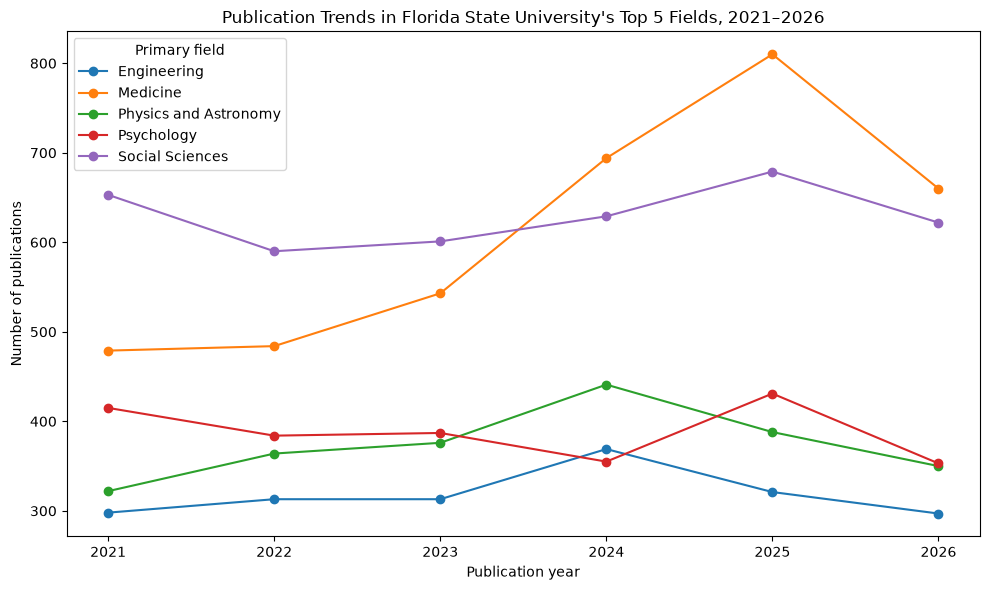

In [91]:
plt.figure(figsize=(10, 6))

for field in yearly_counts.columns:
    plt.plot(yearly_counts.index, yearly_counts[field],
             marker="o", label=field)

plt.title("Publication Trends in Florida State University's Top 5 Fields, 2021–2026")
plt.xlabel("Publication year")
plt.ylabel("Number of publications")
plt.xticks(yearly_counts.index)
plt.legend(title="Primary field")
plt.tight_layout()
plt.show()

Medicine’s publication count increased from 2021 through 2025, overtaking Social Sciences in 2024. The chart hides differences in citation impact, and 2026 is a partial year, so its counts are not directly comparable with complete years.

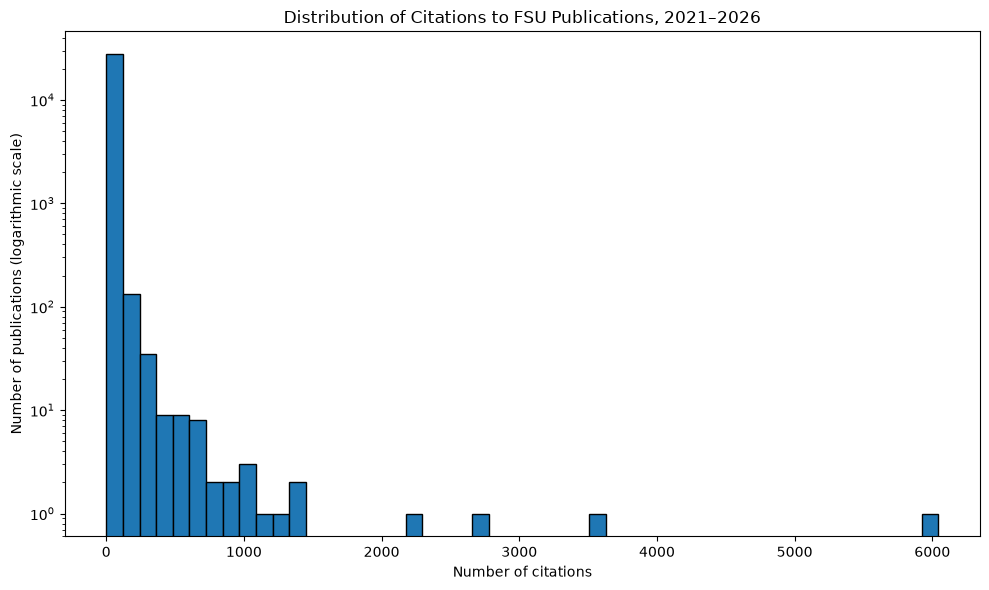

In [92]:
plt.figure(figsize=(10, 6))
plt.hist(df["cited_by_count"], bins=50, log=True, edgecolor="black")
plt.title("Distribution of Citations to FSU Publications, 2021–2026")
plt.xlabel("Number of citations")
plt.ylabel("Number of publications (logarithmic scale)")
plt.tight_layout()
plt.show()

Most Florida State University publications have few citations, while very few have thousands. The chart hides differences between research fields and how long each publication has had to collect citations.

In [93]:
sample_size = 5000
fsu_works = pd.read_csv("fsu_works_2021_2026.csv")

sampled_works = fsu_works.sample(
    n=sample_size,
    replace=False,
    random_state=42
)

print("Total Publications: ", len(fsu_works))
print("Sampled Publications: ", len(sampled_works))

Total Publications:  27830
Sampled Publications:  5000


In [94]:
paper_id = sampled_works.iloc[0]["id"]
short_id = paper_id.split("/")[-1]

response = requests.get(
    f"https://api.openalex.org/works/{short_id}",
    params={"select": "id,referenced_works,related_works"},
    timeout=30
)
response.raise_for_status()

paper_data = response.json()

print("Paper:", paper_data["id"])
print("Number of references:", len(paper_data["referenced_works"]))
print("First five references:", paper_data["referenced_works"][:5])

Paper: https://openalex.org/W4388367951
Number of references: 38
First five references: ['https://openalex.org/W382070501', 'https://openalex.org/W1575537016', 'https://openalex.org/W1963907617', 'https://openalex.org/W1965229818', 'https://openalex.org/W1998441499']


In [95]:
citation_links = []

for number, work in enumerate(sampled_works["id"], start=1):
    short_id = work.split("/")[-1]

    response = requests.get(
        f"https://api.openalex.org/works/{short_id}",
        params={"select": "id, referenced_works, related_works"},
        timeout=30
    )

    response.raise_for_status()
    paper_data = response.json()

    for reference_id in paper_data["referenced_works"]:
        citation_links.append({
            "source": paper_data["id"],
            "target": reference_id
        })

    if number % 100 == 0:
        print(f"Processed {number} papers")

Processed 100 papers
Processed 200 papers
Processed 300 papers
Processed 400 papers
Processed 500 papers
Processed 600 papers
Processed 700 papers
Processed 800 papers
Processed 900 papers
Processed 1000 papers
Processed 1100 papers
Processed 1200 papers
Processed 1300 papers
Processed 1400 papers
Processed 1500 papers
Processed 1600 papers
Processed 1700 papers
Processed 1800 papers
Processed 1900 papers
Processed 2000 papers
Processed 2100 papers
Processed 2200 papers
Processed 2300 papers
Processed 2400 papers
Processed 2500 papers
Processed 2600 papers
Processed 2700 papers
Processed 2800 papers
Processed 2900 papers
Processed 3000 papers
Processed 3100 papers
Processed 3200 papers
Processed 3300 papers
Processed 3400 papers
Processed 3500 papers
Processed 3600 papers
Processed 3700 papers
Processed 3800 papers
Processed 3900 papers
Processed 4000 papers
Processed 4100 papers
Processed 4200 papers
Processed 4300 papers
Processed 4400 papers
Processed 4500 papers
Processed 4600 pape

In [96]:
print(len(citation_links))

197178


In [97]:
all_edges = pd.DataFrame(citation_links)
all_edges.to_csv("paper_citation_links_all.csv", index=False)

In [98]:
fsu_ids = set(fsu_works["id"])

fsu_edges = all_edges[
    all_edges["source"].isin(fsu_ids)
    & all_edges["target"].isin(fsu_ids)
].copy()

fsu_edges.to_csv("paper_citation_links_within_fsu.csv", index=False)

share = len(fsu_edges)/len(all_edges) * 100

print("Number of citation links: ", len(all_edges))
print("FSU internal citation links: ", len(fsu_edges))
print(f"Share of all citation links: {share:.2f}%")



Number of citation links:  197178
FSU internal citation links:  3466
Share of all citation links: 1.76%


I randomly sampled 1,000 FSU works without replacement, using a fixed seed of 42 so the sample can be reproduced. Sampling reduces the number of API requests and makes the network manageable to visualize, but it leaves out citations from works that were not sampled.

In [99]:
G = nx.from_pandas_edgelist(
    fsu_edges,
    source="source",
    target="target",
    create_using=nx.DiGraph()
)

print("Number of papers:", G.number_of_nodes())
print("Number of citation links:", G.number_of_edges())

Number of papers: 3810
Number of citation links: 3466


In [100]:
positions = nx.spring_layout(G, seed=42)

In [101]:
edge_x = []
edge_y = []

for source, target in G.edges():
    x0, y0 = positions[source]
    x1, y1 = positions[target]

    edge_x.extend([x0, x1, None])
    edge_y.extend([y0, y1, None])

edge_trace = go.Scatter(
    x=edge_x,
    y=edge_y,
    mode="lines",
    line=dict(width=0.5, color="gray"),
    hoverinfo="skip"
)

In [102]:
node_x = []
node_y = []
node_ids = []

for paper_id in G.nodes():
    x,y = positions[paper_id]

    node_x.append(x)
    node_y.append(y)
    node_ids.append(paper_id)

In [103]:
node_trace = go.Scatter(
    x=node_x,
    y=node_y,
    mode="markers",
    text=node_ids,
    hoverinfo="text",
    marker=dict(
        size=6,
        color="steelblue",
        opacity=0.6
    )
)

In [104]:
fig = go.Figure(
    data=[edge_trace, node_trace]
)

fig.update_layout(
    title="Citation Links Between Florida State University Publications, 2021–2026",
    showlegend=False,
    dragmode="zoom",
    xaxis=dict(visible=False),
    yaxis=dict(visible=False),
    plot_bgcolor="white",
    width=1000,
    height=700
)

fig.show()